# Step 1 — Load saved results

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT  = Path('/content/drive/MyDrive/m5_project/outputs')
SEED = 0

trial_scores = pd.read_csv(OUT / f'student_trial_scores_seed{SEED}.csv')        # every trial x every judge
results      = pd.read_csv(OUT / f'student_results_seed{SEED}.csv', index_col=0) # final test scores per method
teacher_test = pd.read_csv(OUT / 'teacher_test_rmsse.csv', index_col=0).squeeze()  # teacher per level

print('trial_scores:', trial_scores.shape)
print('results:', results.shape)
print('teacher_test:', teacher_test.round(3).to_dict())

Mounted at /content/drive
trial_scores: (24, 7)
results: (13, 9)
teacher_test: {'L1_total': 0.577, 'L2_store': 0.681, 'L3_cat': 0.612, 'L4_dept': 0.667}


#Step 2 — Table 4 (ours vs paper)
- Final test R_H and level-wise weighted RMSSE (L1–L8) for the store+dept ensemble student,
for every selection method, with the paper's M5 R_H alongside and the gap to Gold.


In [3]:
order = ['Gold', 'TCV-Lowest', 'TCV-Hier', 'TCV-Lowest-PO', 'TCV-Hier-PO',
         'H-Pro-Top', 'H-Pro-Avg', 'H-Pro-Top-PO', 'H-Pro-Avg-PO']

paper_rh = {'Gold': 0.512, 'TCV-Hier': 0.534, 'H-Pro-Top': 0.512, 'H-Pro-Avg': 0.534,
            'H-Pro-Top-PO': 0.521, 'H-Pro-Avg-PO': 0.534}             # paper Table 4 (full M5)

table4 = results.loc[order].copy()
table4.insert(1, 'paper_R_H (M5)', pd.Series(paper_rh))
table4.insert(2, 'gap_to_Gold_%', (table4['R_H'] / table4.loc['Gold', 'R_H'] - 1) * 100)

table4.round(3).to_csv(OUT / 'table4_ours.csv')
table4.round(3)

,R_H,paper_R_H (M5),gap_to_Gold_%,L1_total,L2_store,L3_cat,L4_dept,L5_store_cat,L6_store_dept,L7_item,L8_item_store
Gold,0.745,0.512,0.000,0.703,0.716,0.690,0.688,0.724,0.728,0.863,0.850
TCV-Lowest,0.745,NaN,0.000,0.703,0.716,0.690,0.688,0.724,0.728,0.863,0.850
TCV-Hier,0.745,0.534,0.000,0.703,0.716,0.690,0.688,0.724,0.728,0.863,0.850
TCV-Lowest-PO,0.782,NaN,4.966,0.757,0.772,0.738,0.731,0.770,0.768,0.865,0.853
TCV-Hier-PO,0.754,NaN,1.208,0.717,0.729,0.703,0.699,0.735,0.737,0.864,0.851
H-Pro-Top,0.745,0.512,0.000,0.703,0.716,0.690,0.688,0.724,0.728,0.863,0.850
H-Pro-Avg,0.745,0.534,0.000,0.703,0.716,0.690,0.688,0.724,0.728,0.863,0.850
H-Pro-Top-PO,0.748,0.521,0.403,0.706,0.720,0.694,0.690,0.728,0.730,0.863,0.851
H-Pro-Avg-PO,0.750,0.534,0.671,0.712,0.724,0.699,0.694,0.730,0.730,0.863,0.850


# Step 3 — Table 5 (teacher test RMSSE per level)
Teacher's proxy accuracy on the test month at L1–L4, next to the final student (H-Pro-Top, store+dept)
at the same levels and the paper's M5 teacher.

In [4]:
paper_teacher = pd.Series({'L1_total': 0.1832, 'L2_store': 0.5850,
                           'L3_cat': 0.4958, 'L4_dept': 0.5871})          # paper Table 5 (M5)

table5 = pd.DataFrame({
    'teacher (ours)':           teacher_test,                                  # proxies vs real test
    'student H-Pro-Top (ours)': results.loc['H-Pro-Top', teacher_test.index],  # added-up student vs real test
    'teacher (paper M5)':       paper_teacher,
})
table5['teacher better?'] = table5['teacher (ours)'] < table5['student H-Pro-Top (ours)']

table5.round(3).to_csv(OUT / 'table5_ours.csv')
table5.round(3)

,teacher (ours),student H-Pro-Top (ours),teacher (paper M5),teacher better?
L1_total,0.577,0.703,0.183,True
L2_store,0.681,0.716,0.585,True
L3_cat,0.612,0.690,0.496,True
L4_dept,0.667,0.688,0.587,True


# Step 4 — Table 6 (ensembles)

- Mean-of-forecast ensembles as in the paper (Sec 5.5.2)

In [5]:
ens = ['Ens (1)', 'Ens (2)', 'Ens (3)', 'Ens (4)']
tcv = ['TCV-Lowest', 'TCV-Lowest-PO', 'TCV-Hier', 'TCV-Hier-PO']

table6 = pd.DataFrame({
    'ours (R_H)': list(results.loc[ens, 'R_H']) + [results.loc[tcv, 'R_H'].min()],
    'paper (M5)': [0.520, 0.520, 0.519, 0.521, 0.534],
}, index=ens + ['Best baseline (TCV)'])

table6.round(3).to_csv(OUT / 'table6_ours.csv')
table6.round(3)

,ours (R_H),paper (M5)
Ens (1),0.745,0.520
Ens (2),0.748,0.520
Ens (3),0.746,0.519
Ens (4),0.746,0.521
Best baseline (TCV),0.745,0.534


# Step 5 — Fig 1 (selection objective vs true test error)

- which judge predicts the future best?

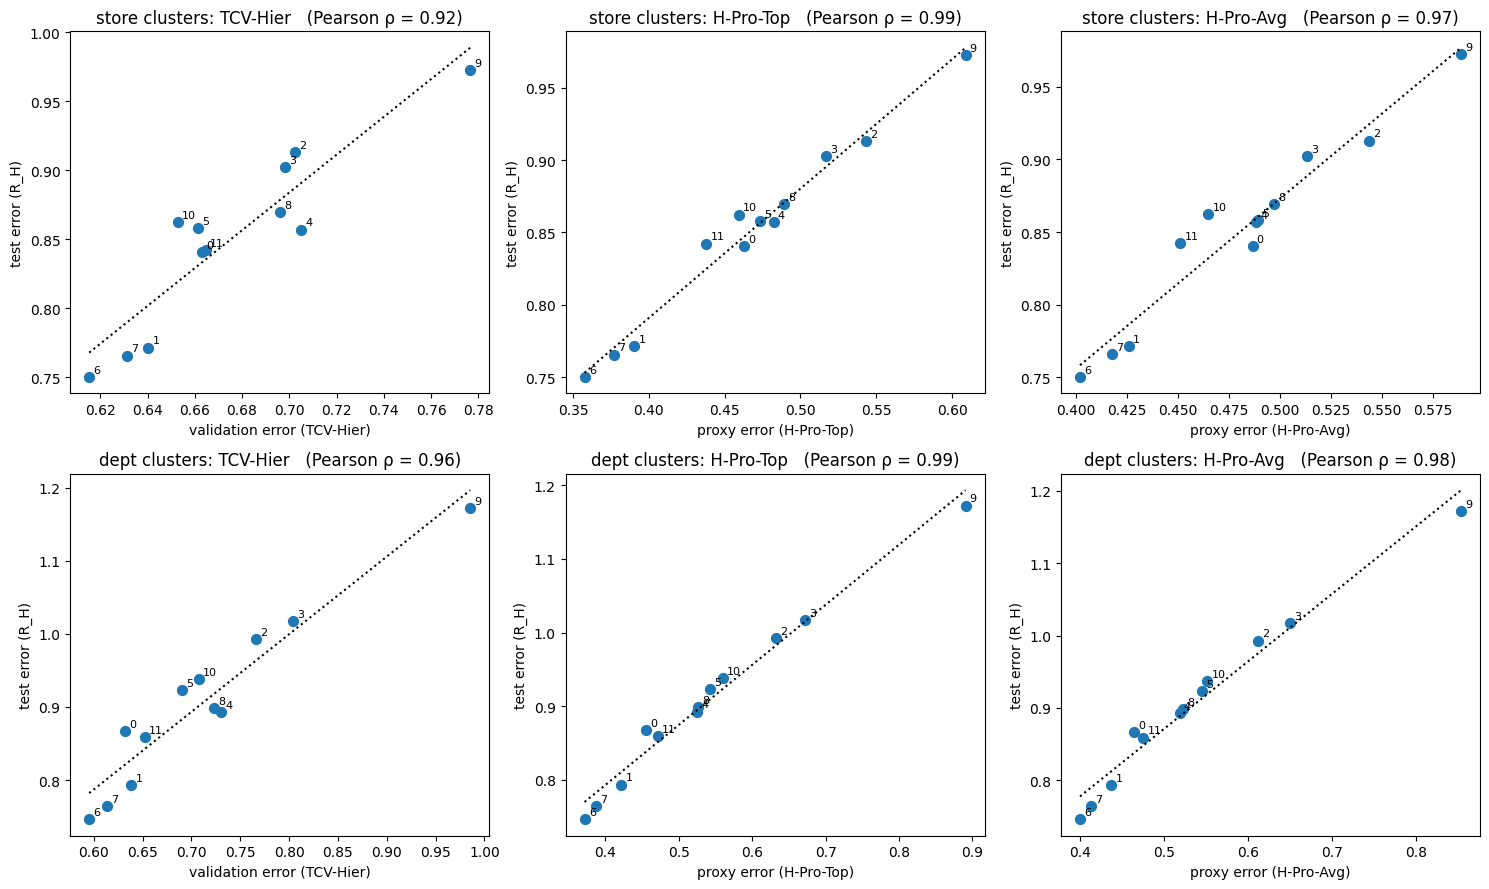

       H-Pro-Avg  H-Pro-Top  TCV-Hier
dept        0.98       0.99      0.96
store       0.97       0.99      0.92


In [6]:
judges = {'TCV-Hier':  'validation error (TCV-Hier)',
          'H-Pro-Top': 'proxy error (H-Pro-Top)',
          'H-Pro-Avg': 'proxy error (H-Pro-Avg)'}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
corr = {}
for r, set_name in enumerate(['store', 'dept']):
    data = trial_scores[trial_scores.set == set_name]
    for c, (method, label) in enumerate(judges.items()):
        ax = axes[r, c]
        x, y = data[method], data['Gold']                      # judge's grade vs real test grade
        rho = np.corrcoef(x, y)[0, 1]                           # Pearson correlation (as in the paper)
        corr[(set_name, method)] = rho
        ax.scatter(x, y, s=50)
        for t, xi, yi in zip(data.trial, x, y):                 # label each dot with its trial number
            ax.annotate(str(t), (xi, yi), xytext=(3, 3), textcoords='offset points', fontsize=8)
        slope, intercept = np.polyfit(x, y, 1)                  # dotted trend line (as in the paper)
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, slope * xs + intercept, 'k:')
        ax.set_title(f'{set_name} clusters: {method}   (Pearson ρ = {rho:.2f})')
        ax.set_xlabel(label)
        ax.set_ylabel('test error (R_H)')

plt.tight_layout()
plt.savefig(OUT / 'fig1_ours.png', dpi=150)
plt.show()
print(pd.Series(corr).unstack().round(2))

# Saving results to reports folder

In [7]:
import shutil
REP = OUT.parent / 'reports'          # m5_project/reports
REP.mkdir(exist_ok=True)
for f in ['table4_ours.csv', 'table5_ours.csv', 'table6_ours.csv', 'student_results_seed0.csv',
          'student_trial_scores_seed0.csv', 'teacher_test_rmsse.csv', 'fig1_ours.png']:
    shutil.copy(OUT / f, REP / f)
print(sorted(p.name for p in REP.iterdir()))

['fig1_ours.png', 'student_results_seed0.csv', 'student_trial_scores_seed0.csv', 'table4_ours.csv', 'table5_ours.csv', 'table6_ours.csv', 'teacher_test_rmsse.csv']
